# Phase 3: the coupled engine model

Phases 1 and 2 built the pieces: a cycle model that needs component efficiencies *assumed*, and meanline models that *compute* a compressor's and a turbine's performance from geometry. Phase 3 couples them on one shaft. At each shaft speed the engine settles where three conditions hold together (*matching*):

1. **power balance**: the turbine drives the compressor, $\eta_m P_t = P_c$;
2. **turbine flow capacity**: the turbine swallows exactly the air plus fuel the compressor delivers;
3. **nozzle flow capacity**: the fixed nozzle area passes that flow.

Unknowns are air mass flow, turbine inlet temperature (TIT, i.e. fuel flow) and turbine pressure ratio; a Newton solver finds them. To make this fast enough we first wrote our own **fast axial turbine model** (TurboFlow's equations, marching solver) and verified it against TurboFlow.

> Preliminary design only, not manufacturing-ready: everything here is a meanline/0-D model.

In [1]:
import os, warnings
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt, yaml
from IPython.display import Markdown, display
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd(); os.chdir(ROOT)
warnings.filterwarnings('ignore')
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
INK, MUTED, GRID = '#1f1f1e', '#6b6a63', '#e4e3dd'
plt.rcParams.update({'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED,
    'ytick.color': MUTED, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'lines.linewidth': 2, 'font.size': 10})
P3 = ROOT / 'validation' / 'phase3'

## 1. Fast turbine model vs TurboFlow and vs measurement (Kofskey 1972)
Same equations as TurboFlow (Benner losses, Aungier deviation, critical-Mach choking), solved plane by plane instead of all at once. Lines: our model; open circles: TurboFlow; filled dots: NASA measurements. The lines sit on the circles (port verification); both differ from the measurements by the same model error (validation).

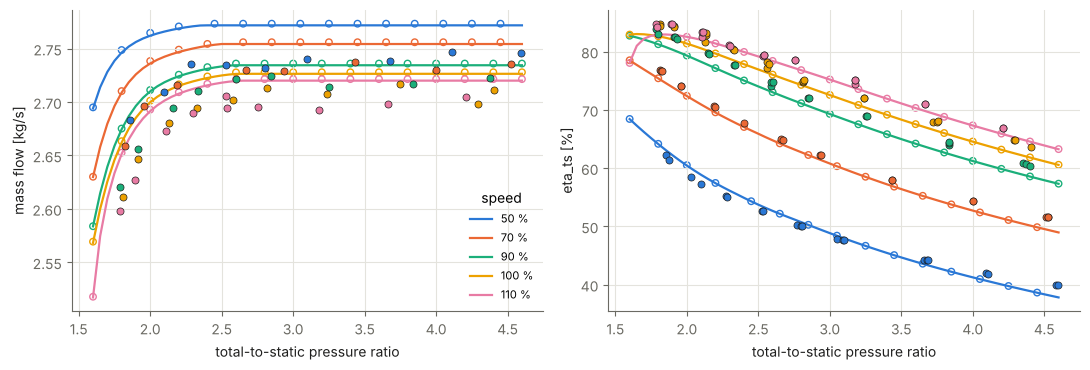

,turboflow,rotor_plus
n,278.000,278.000
mass_flow_max_abs_pct,0.099,1.718
eta_ts_max_abs_pts,0.061,4.268
power_max_abs_pct,0.123,7.454
eta_vs_meas_mean_pts,-1.200,-2.000
mdot_vs_meas_mean_%,1.080,0.760
time_ms,8.690,8.780


In [2]:
fm = pd.read_csv(P3 / 'kofskey_fast_map.csv'); tf = pd.read_csv('validation/phase2/kofskey_map.csv')
meas = pd.read_csv('validation/cases/kofskey1972_turbine_measured.csv', comment='#')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i, sp in enumerate([50, 70, 90, 100, 110]):
    f = fm[(fm.incidence_sign == 'turboflow') & (fm.speed_pct_design == sp) & fm.converged]
    t = tf[(tf.speed_pct_design == sp) & tf.converged]
    for ax, col, q, sc in [(axes[0], 'mass_flow_kg_s', 'mass_flow', 1), (axes[1], 'eta_ts', 'efficiency_ts', 100)]:
        ax.plot(f.pr_ts, f[col] * sc, color=SERIES[i], lw=1.6, label=f'{sp} %')
        ax.scatter(t.pr_ts[::4], t[col][::4] * sc, s=22, facecolor='none', edgecolor=SERIES[i])
        m = meas[(meas.speed_pct_design == sp) & (meas.quantity == q)]
        ax.scatter(m.pressure_ratio_ts, m.value, s=26, color=SERIES[i], edgecolor=INK, linewidth=0.5, zorder=4)
axes[0].set(xlabel='total-to-static pressure ratio', ylabel='mass flow [kg/s]'); axes[1].set(xlabel='total-to-static pressure ratio', ylabel='eta_ts [%]')
axes[0].legend(title='speed', frameon=False, fontsize=8); plt.tight_layout(); plt.show()
S = yaml.safe_load((P3 / 'kofskey_fast_summary.yaml').read_text())
pd.DataFrame({m: {**S[m]['vs_turboflow_map'], 'eta_vs_meas_mean_pts': S[m]['vs_measured']['efficiency_ts']['mean_pts'],
              'mdot_vs_meas_mean_%': S[m]['vs_measured']['mass_flow']['mean_%'], 'time_ms': S[m]['time_ms_median_sweep']}
              for m in ('turboflow', 'rotor_plus')})

**The incidence-sign question.** TurboFlow's code intends a different incidence sign for rotors (`rotor_plus`) but, through a small bug, uses the stator sign everywhere. Surprisingly, the buggy version fits the measurements *better* (at 50 % speed the rotor sees +27 deg incidence, and the measured efficiency there is not penalised as much as the intended sign predicts). We keep the TurboFlow behaviour as default and ask for the Benner et al. (1997) paper to settle it.

## 2. Verification across the design space (Sobol samples)
Stages sized from random-but-even (Sobol) choices of flow coefficient, loading, reaction, aspect ratio, clearance, work, mass flow, speed, inlet temperature/pressure, and an off-design point. Acceptance: efficiency within 2 points, mass flow and work within 2 %.

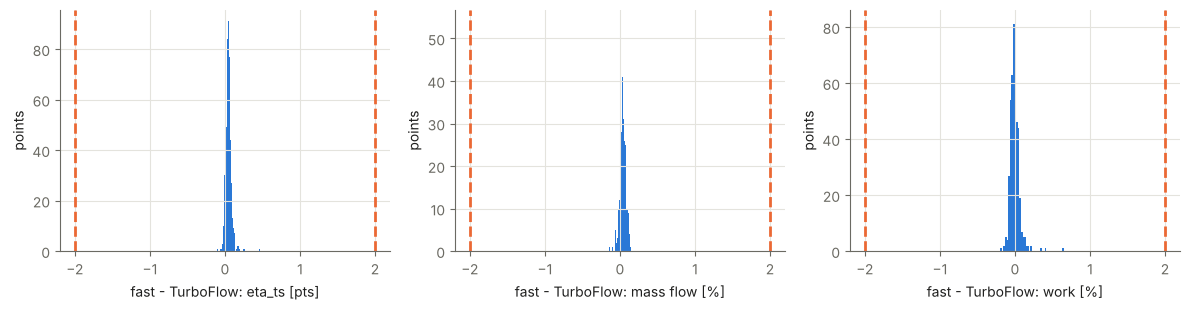

samples: 256
points: 458
status_counts:
  compared: 454
  'sizing_failed: blade height exceeds the mean diameter (hub radius <= 0): flow coefficient too low': 27
  tf_failed: 4
accepted: true
fast_time_ms_median_cold: 34.2
tf_time_s_median: 18.76



,sample,point,score,d_eta_ts_pts,d_mdot_pct,d_work_pct,phi,psi,reaction,mdot_design_kg_s,rpm_design,T0_in_K,pr_ts_eval,speed_frac_eval,hub_tip_min,fast_choked,fast_rotor_incidence_deg,n_warnings
0,235,off_design,0.3255,0.4714,0.0482,0.6510,0.8763,1.2746,0.2691,0.3383,108938.0476,1047.7170,2.3419,0.7087,0.8072,stator,12.2368,0.0
1,11,off_design,0.2068,0.2495,0.0445,0.4136,0.8900,0.9859,0.2390,1.2524,99072.4518,1167.9566,2.4413,0.6503,0.3054,stator,16.1003,2.0
2,79,off_design,0.1678,0.2663,0.0441,0.3356,0.6253,1.0075,0.3068,0.1335,146898.7404,1050.9772,2.9128,0.6269,0.8677,stator,22.8259,0.0
3,11,design,0.1098,0.1531,0.0445,0.2195,0.8900,0.9859,0.2390,1.2524,99072.4518,1167.9566,2.6638,1.0000,0.3054,stator,-3.5174,2.0
4,107,design,0.1063,0.1756,-0.0026,0.2125,0.8801,1.2183,0.3265,0.5309,100432.9761,1070.9758,2.1974,1.0000,0.5149,,-0.6204,0.0
5,231,off_design,0.0972,-0.1091,0.0250,-0.1943,0.7342,1.5250,0.3138,0.3039,117899.8500,1086.6432,3.1698,0.8193,0.5705,stator,8.5920,0.0
6,7,off_design,0.0971,0.1942,0.0405,0.1702,0.7571,1.0739,0.3939,0.8715,109107.2220,1141.3355,2.2863,0.7843,0.6555,stator,15.6980,0.0
7,202,off_design,0.0917,0.1808,0.0543,0.1835,0.5934,1.9947,0.2039,0.1156,174267.0624,1101.9179,2.6747,0.9173,0.4958,stator,1.3554,1.0


In [3]:
sob = pd.read_csv(P3 / 'turbine_port_sobol.csv'); SS = yaml.safe_load((P3 / 'turbine_port_summary.yaml').read_text())
c = sob[sob.status == 'compared']
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, col, lab in zip(axes, ['d_eta_ts_pts', 'd_mdot_pct', 'd_work_pct'], ['eta_ts [pts]', 'mass flow [%]', 'work [%]']):
    ax.hist(c[col], bins=40, color=SERIES[0]); ax.axvline(-2, color=SERIES[1], ls='--'); ax.axvline(2, color=SERIES[1], ls='--')
    ax.set(xlabel=f'fast - TurboFlow: {lab}', ylabel='points')
plt.tight_layout(); plt.show()
print(yaml.safe_dump({k: SS[k] for k in ('samples', 'points', 'status_counts', 'accepted', 'fast_time_ms_median_cold', 'tf_time_s_median')}, sort_keys=False))
pd.DataFrame(SS['worst_cases'])

## 3. The baseline engine (design card)
A ~150 N engine sized by the design mode. All numbers are physics-evaluated.

In [4]:
display(Markdown((P3 / 'baseline_design_card.md').read_text()))

# TurboML baseline engine (Phase 3)

> **PRELIMINARY DESIGN ONLY - NOT MANUFACTURING-READY. Real micro turbines spin at 100 000+ rpm and need detailed 3-D aerodynamic, structural, rotordynamic, thermal and combustion analysis plus physical testing by qualified people before anything is built or run.**

Status: physics-evaluated design point (0-D cycle + meanline components); not surrogate output.

## Design point

| quantity | value |
|---|---|
| net thrust | 148.3 N |
| air mass flow | 0.300 kg/s |
| specific thrust | 494 N s/kg |
| TSFC | 41.5 g/(kN s) (0.150 kg/(N h)) |
| fuel flow | 6.16 g/s |
| shaft speed | 130000 rpm |
| compressor PR / eta_tt | 3.000 / 0.751 |
| TIT | 1150 K |
| turbine PR_ts / eta_ts | 1.855 / 0.742 |
| EGT (turbine exit total) | 1033 K (759 C) |
| nozzle area A9 | 16.70 cm2 (subsonic) |

## Geometry (meanline)

| part | value |
|---|---|
| impeller tip radius r2 | 35.39 mm (tip speed 482 m/s) |
| inducer hub / tip radius | 6.56 / 23.63 mm |
| impeller exit width b2 | 4.65 mm |
| blades / backsweep | 10 / -21 deg |
| diffuser outlet radius | 51.5 mm (vaneless model) |
| turbine mean radius | 27.55 mm |
| turbine rotor tip radius / blade height | 34.44 / 13.79 mm |
| turbine blades (stator / rotor, non-integer sizing) | 28.1 / 22.5 |
| envelope D x L (proxy) | 115 x 298 mm |
| dry mass (proxy) | 1.71 +- 0.17 kg |

## Constraints and proxies

- material: in713c; metal temperature basis TIT - gas_to_metal_allowance (nozzle guide vanes): 1150 K; margins in713c +103 K, marm247 +123 K
- rotor inlet relative total temperature: 1088 K
- impeller tip speed 482 m/s (limit 500)
- blade root stress proxy: 557 MPa (unchecked: material_data_missing); AN^2 = 4.03e+07 m2 rpm2
- feasible: True
- tags: blade stress unchecked (allowable stress not sourced)

## Off-design (physics-evaluated, speed-controlled)

| point | N [rpm] | alt [m] | Mach | Fn [N] | TSFC [g/(kN s)] | m_air [kg/s] | PR_c | TIT [K] | EGT [K] | status |
|---|---|---|---|---|---|---|---|---|---|---|
| design_check | 130000 | 0 | 0.00 | 148.3 | 41.5 | 0.300 | 3.000 | 1150 | 1033 | ok |
| cruise_M05_3km | 130000 | 3000 | 0.50 | 99.5 | 48.4 | 0.257 | 3.052 | 1087 | 968 | ok |
| part_speed_80 | 104000 | 0 | 0.00 | 72.3 | 52.0 | 0.216 | 2.047 | 1007 | 931 | ok |
| part_speed_60 | 78000 | 0 | 0.00 | 33.3 | 73.8 | 0.146 | 1.503 | 954 | 912 | ok |
| idle_35 | 45500 | 0 | 0.00 | 9.5 | 139.1 | 0.077 | 1.150 | 942 | 927 | ok |

Component assumptions: configs/engine_baseline.yaml (DePaola 2020 values as summarised by the user; compressor calibration from the KJ-66, provisional).


In [5]:
B = yaml.safe_load((P3 / 'baseline_summary.yaml').read_text())
pl = B['plausibility']
rows = {'specific thrust [N s/kg]': (pl['specific_thrust_N_s_kg']['model'], pl['specific_thrust_N_s_kg']['database_range_lt_250N']),
        'TSFC [g/(kN s)]': (pl['TSFC_g_kN_s']['model'], pl['TSFC_g_kN_s']['db_min_median_max_n'][:3]),
        'shaft speed [rpm]': (pl['shaft_speed_rpm']['model'], pl['shaft_speed_rpm']['db_min_median_max_n'][:3]),
        'diameter [mm]': (pl['diameter_mm']['model_proxy'], pl['diameter_mm']['db_min_median_max_n'][:3]),
        'length [mm]': (pl['length_mm']['model_proxy'], pl['length_mm']['db_min_median_max_n'][:3]),
        'EGT [C]': (pl['EGT_C']['model'], pl['EGT_C']['db_min_median_max_n'][:3])}
print(pl['comparison_set'])
pd.DataFrame(rows, index=['model', 'database (min, median, max)']).T

review table engines with thrust 104-193 N (n = 32)


,model,"database (min, median, max)"
specific thrust [N s/kg],494.3,"[352, 511]"
TSFC [g/(kN s)],41.55,"[37.963, 46.418, 54.517]"
shaft speed [rpm],130000,"[115000.0, 126500.0, 175000.0]"
diameter [mm],115.2,"[90.0, 103.0, 120.0]"
length [mm],298.3,"[198.0, 283.0, 346.0]"
EGT [C],759.4,"[680.0, 700.0, 760.0]"


**Cross-check.** With the component efficiencies the coupled model produced, the 0-D cycle and pyCycle-CEA give the same thrust and TSFC:

In [6]:
pd.DataFrame({k: v for k, v in B['cross_check_design_point'].items() if k in ('coupled', 'cycle_simple', 'pycycle_cea')})

,coupled,cycle_simple,pycycle_cea
Fn_N,148.2860,148.2860,148.3160
TSFC_g_kN_s,41.5489,41.5489,41.5799


## 4. Operating line (sea level, speed-controlled)
The ECU of a model turbojet sets the shaft speed; thrust, fuel flow and temperatures follow. Below about 30 % speed the nozzle has no pressure ratio left (labelled, not dropped).

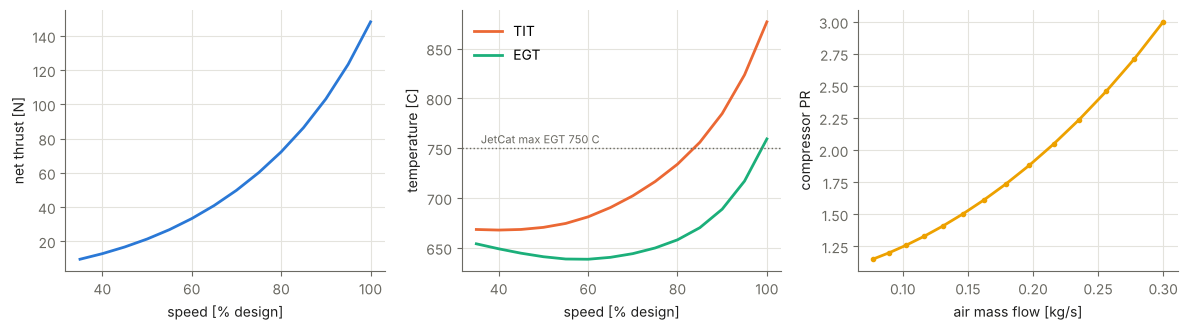

,n_frac,failure_reason
14,0.3,no_nozzle_pressure_ratio


In [7]:
ol = pd.read_csv(P3 / 'baseline_operating_line.csv'); ok = ol[ol.converged]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].plot(ok.n_frac * 100, ok.Fn_N, color=SERIES[0]); axes[0].set(xlabel='speed [% design]', ylabel='net thrust [N]')
axes[1].plot(ok.n_frac * 100, ok.tit_K - 273.15, color=SERIES[1], label='TIT'); axes[1].plot(ok.n_frac * 100, ok.T05_K - 273.15, color=SERIES[2], label='EGT')
axes[1].axhline(750, color=MUTED, ls=':', lw=1); axes[1].text(36, 755, 'JetCat max EGT 750 C', color=MUTED, fontsize=8)
axes[1].set(xlabel='speed [% design]', ylabel='temperature [C]'); axes[1].legend(frameon=False)
axes[2].plot(ok.W_air_kg_s, ok.pr_c, 'o-', color=SERIES[3], ms=3); axes[2].set(xlabel='air mass flow [kg/s]', ylabel='compressor PR')
plt.tight_layout(); plt.show()
ol.loc[~ol.converged, ['n_frac', 'failure_reason']]

## 5. Materials: where TIT becomes a constraint
The TIT bound is now 1000-1350 K. Feasibility comes from the turbine material (`configs/materials.yaml`): IN-713C (default) to 1253 K, MAR-M 247 (premium) to 1273 K, with zero gas-to-metal allowance. Above the default material: tagged *premium material required*; above all: infeasible but kept in the data.

In [8]:
from turboml.physics import mechanical as mech
M = mech.MaterialSet.from_yaml()
pd.DataFrame([{'TIT [K]': T, **{k: v for k, v in mech.turbine_temperature_check(T, M).items() if k in ('material', 'premium_material_required', 'feasible')}}
              for T in (1100, 1200, 1250, 1260, 1270, 1280, 1350)])

,TIT [K],material,feasible,premium_material_required
0,1100,in713c,True,False
1,1200,in713c,True,False
2,1250,in713c,True,False
3,1260,marm247,True,True
4,1270,marm247,True,True
5,1280,None,False,False
6,1350,None,False,False


## 6. Try it: one off-design point (a few seconds)

In [9]:
import time
from turboml.physics.engine import Engine, design_engine, load_engine_config
cfg = load_engine_config(); d = design_engine(cfg['baseline_design'], cfg); e = Engine(d, cfg)
t0 = time.perf_counter(); p = e.off_design(0.9 * d.design_point.n_rpm, alt_m=1000.0, mach=0.3)
print(f'{time.perf_counter() - t0:.1f} s:', {k: round(v, 3) if isinstance(v, float) else v for k, v in p.to_dict().items()
      if k in ('converged', 'failure_reason', 'Fn_N', 'W_air_kg_s', 'pr_c', 'tit_K', 'T05_K', 'TSFC_g_kN_s')})

5.5 s: {'converged': True, 'failure_reason': '', 'W_air_kg_s': np.float64(0.248), 'Fn_N': np.float64(76.888), 'pr_c': np.float64(2.458), 'tit_K': np.float64(1006.352), 'T05_K': np.float64(909.554), 'TSFC_g_kN_s': np.float64(54.214)}
